In [30]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
import logging
from datetime import datetime, timedelta
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, log_loss
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
import optuna
import time
import json

In [31]:
# Configuration des visualisations
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['font.size'] = 12
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Configuration du logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)
logger = logging.getLogger(__name__)

def load_data():
    """Charge les données du fichier CSV et effectue les conversions de base"""
    # Définir le chemin vers le fichier
    file_path = Path.home() / "Desktop" / "f1_data_pitstop.csv"

    # Vérifier l'existence du fichier
    if not file_path.exists():
        raise FileNotFoundError(f"Le fichier {file_path} n'existe pas")

    # Charger les données
    logger.info("Chargement des données...")
    df = pd.read_csv(file_path, index_col=0)

    # Conversion des colonnes de date
    date_columns = [col for col in df.columns if 'date' in col.lower()]
    for col in date_columns:
        df[col] = pd.to_datetime(df[col], format='mixed', utc=True)

    logger.info(f"Données chargées : {df.shape[0]} lignes et {df.shape[1]} colonnes")
    return df

In [32]:
def split_data_chronologically(X, y, session_keys, categorical_features, label_encoder):
    """Divise les données en ensembles d'entraînement et de test en respectant l'ordre chronologique des courses.

    Args:
        X (pd.DataFrame): Features
        y (np.array): Labels encodés
        session_keys (pd.Series): Clés de session pour le split (utilisées pour le logging)
        categorical_features (list): Liste des features catégorielles
        label_encoder (LabelEncoder): Encodeur des labels

    Returns:
        tuple: X_train, X_test, y_train, y_test, categorical_features, label_encoder
    """
    logger.info("Division des données en respectant l'ordre chronologique...")

    # 1. Trouver la date de split (47ème session unique après le tri)
    unique_session_dates = sorted(X['session_date_start'].unique())

    # Assurer qu'il y a suffisamment de sessions uniques
    if len(unique_session_dates) < 47:
        error_msg = f"Pas assez de sessions uniques pour effectuer le split (seulement {len(unique_session_dates)})."
        logger.error(error_msg)
        raise ValueError(error_msg)

    split_date = unique_session_dates[46]
    logger.info(f"Date de split (47ème date de session unique) : {split_date}")

    # 2. Diviser les données en fonction de la date de split
    X_train = X[X['session_date_start'] < split_date]
    X_test = X[X['session_date_start'] >= split_date]
    y_train = y[X['session_date_start'] < split_date]
    y_test = y[X['session_date_start'] >= split_date]

    # Logging des statistiques
    logger.info(f"Nombre total de sessions uniques : {len(unique_session_dates)}")
    logger.info(f"Sessions uniques (triées par date) : {unique_session_dates}")
    logger.info(f"Features catégorielles ({len(categorical_features)}): {', '.join(categorical_features)}")
    logger.info(f"Features temporelles ({len(X.select_dtypes(include=['datetime64[ns, UTC]']).columns)})")
    logger.info(f"Distribution des classes (train):\n{pd.Series(y_train).value_counts(normalize=True)}")
    logger.info(f"Distribution des classes (test):\n{pd.Series(y_test).value_counts(normalize=True)}")
    logger.info(f"Nombre de courses dans l'ensemble d'entraînement: {len(X_train['session_key'].unique())}")
    logger.info(f"Nombre de courses dans l'ensemble de test: {len(X_test['session_key'].unique())}")

    return X_train, X_test, y_train, y_test, categorical_features, label_encoder

In [33]:
def prepare_data(df):
    """Prépare les données pour l'entraînement du modèle.
    
    Args:
        df (pd.DataFrame): Le DataFrame contenant les données.
        
    Returns:
        tuple: X_train, X_test, y_train, y_test, categorical_features, label_encoder
    """
    logger.info("Préparation des données...")

    # Remplacer toutes les occurrences de `nan` par `NaN`
    df.replace([np.nan, math.nan, 'nan', 'NaN'], pd.NA, inplace=True)

    # Trier les données
    logger.info("Tri des données par session_date_start, driver_number, et lap_number...")
    df = df.sort_values(by=['session_date_start', 'driver_number', 'lap_number'])

    # Séparation des features et de la target
    X = df.drop('pit_window', axis=1)
    y = df['pit_window']

    # Conversion des labels en entiers
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(y)

    # Conversion des colonnes catégorielles
    categorical_features = []
    for col in X.columns:
        if (X[col].dtype.name in ['object']):
            X[col] = pd.Categorical(X[col].astype('category'))
            categorical_features.append(col)

    # Conversion des dates
    date_cols = X.select_dtypes(include=['datetime64[ns, UTC]']).columns
    for col in date_cols:
        X[col] = pd.to_numeric(X[col], errors='coerce') / 1e9

    # Split chronologique des données
    return split_data_chronologically(X, y, df['session_key'], categorical_features, label_encoder)


In [34]:
def objective(trial, X_train, y_train, categorical_cols):
    """Fonction objectif pour l'optimisation des hyperparamètres avec Optuna."""
    try:
        param = {
            # Paramètres de base (inchangés)
            "objective": "multiclass",
            'metric': ['multi_logloss', 'auc_mu'],
            'boosting_type': ['gbdt'],
            'num_class': len(np.unique(y_train)),
            'verbosity': -1,
            'boost_from_average': False,
            'seed': 42,

            # Paramètres de régularisation (plages plus restreintes)
            'lambda_l1': trial.suggest_float('lambda_l1', 0, 3),
            'lambda_l2': trial.suggest_float('lambda_l2', 0, 3),
            'min_gain_to_split': trial.suggest_float('min_gain_to_split', 0, 2),

            # Paramètres de l'arbre (optimisation autour des valeurs des meilleurs essais)
            'num_leaves': trial.suggest_int('num_leaves', 90, 150),
            'max_depth': trial.suggest_int('max_depth', 6, 12),
            'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 10, 50),
            'min_sum_hessian_in_leaf': trial.suggest_float('min_sum_hessian_in_leaf', 2, 4),

            # Paramètres de sous-échantillonnage (favoriser les valeurs plus basses)
            'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 0.9),
            'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 0.6),
            'bagging_freq': trial.suggest_int('bagging_freq', 5, 7),

            # Paramètres d'apprentissage (légèrement plus restrictif)
            'learning_rate': trial.suggest_float('learning_rate', 0.07, 0.1),

            # Paramètres de binning (autour des valeurs des meilleurs essais)
            "max_bin": trial.suggest_int("max_bin", 100, 200),
            "min_data_in_bin": trial.suggest_int("min_data_in_bin", 10, 20),

            # Paramètres pour les catégorielles (autour des valeurs des meilleurs essais)
            "cat_smooth": trial.suggest_float("cat_smooth", 80, 100)
        }

        # Dataset LightGBM avec gestion explicite des catégorielles et des noms de features
        dtrain = lgb.Dataset(
            X_train,
            label=y_train.astype(int),
            categorical_feature=list(categorical_cols),
            feature_name=list(X_train.columns)
        )

        # CV avec early stopping
        cv_results = lgb.cv(
            params=param,
            train_set=dtrain,
            num_boost_round=2000,
            nfold=5,
            stratified=True,
            seed=42,
            callbacks=[
                lgb.early_stopping(stopping_rounds=200, verbose=True),
                lgb.log_evaluation(period=0)
            ],
            return_cvbooster=True
        )

        # Récupération du meilleur score et de la meilleure itération
        best_score = min(cv_results['valid multi_logloss-mean'])
        best_iter = len(cv_results['valid multi_logloss-mean'])

        if not np.isfinite(best_score):
            logger.warning(f"Score non valide obtenu: {best_score}")
            return float('inf')

        logger.info(f"Trial terminé avec succès - Score: {best_score:.4f} à l'itération {best_iter}")
        
        # Stocker la meilleure itération
        trial.set_user_attr("best_iteration", best_iter)

        return best_score

    except Exception as e:
        logger.error(f"Erreur dans l'objectif: {str(e)}")
        return float('inf')

In [35]:
def train_final_model(study, X_train, X_test, y_train, y_test, cat_features):
    """
    Entraîne le modèle final avec les meilleurs paramètres trouvés.
    """
    logger.info("Entraînement du modèle final...")

    best_params = study.best_params
    best_iteration = study.best_trial.user_attrs["best_iteration"]

    # Ajustement des paramètres pour le modèle final
    final_params = {
        **best_params,
        'objective': 'multiclass',
        'metric': 'multi_logloss',
        'num_class': len(np.unique(y_train)),
        'categorical_feature': cat_features,
        # 'verbosity': -1, # On garde les logs pour le modèle final
        'learning_rate': best_params['learning_rate'] * 0.8,
    }

    # Création des datasets
    train_data = lgb.Dataset(
        X_train,
        label=y_train,
        categorical_feature=cat_features,
        feature_name=list(X_train.columns)
    )
    valid_data = lgb.Dataset(
        X_test,
        label=y_test,
        reference=train_data,
        feature_name=list(X_test.columns)
    )

    # Entraînement avec early stopping
    final_model = lgb.train(
        final_params,
        train_data,
        num_boost_round=int(best_iteration * 1.2), # On utilise la meilleure itération trouvée
        valid_sets=[valid_data],
        callbacks=[
            lgb.early_stopping(stopping_rounds=200, verbose=True),
            lgb.log_evaluation(period=100)
        ]
    )

    logger.info(f"Entraînement terminé après {final_model.best_iteration} itérations")

    # Évaluation du modèle final
    y_pred_prob = final_model.predict(X_test)

    # Correction du nombre de colonnes de y_pred_prob pour correspondre à y_test
    classes_in_test = sorted(np.unique(y_test))
    y_pred_prob_corrected = y_pred_prob[:, classes_in_test]

    final_logloss = log_loss(y_test, y_pred_prob_corrected)
    logger.info(f"Log loss du modèle final: {final_logloss:.4f}")

    return final_model

In [36]:
def evaluate_model_with_probabilities(model, X_test, y_test, label_encoder):
    """Évalue le modèle avec analyse détaillée des probabilités"""
    logger.info("Évaluation du modèle et analyse des probabilités...")

    # Obtention des probabilités pour chaque classe
    y_pred_proba = model.predict(X_test)
    y_pred_classes = np.argmax(y_pred_proba, axis=1)

    # Conversion pour les labels originaux
    y_pred_classes_original = label_encoder.inverse_transform(y_pred_classes)
    y_test_original = label_encoder.inverse_transform(y_test)

    # Calcul des métriques de base
    class_labels = sorted(label_encoder.classes_, key=lambda x: ('Never' in x, x))
    
    # Rapport de classification standard
    report = classification_report(y_test_original, y_pred_classes_original)
    logger.info("\nRapport de classification:\n" + report)

    # Analyse des probabilités
    logger.info("\nAnalyse des probabilités par classe:")
    mean_probas = y_pred_proba.mean(axis=0)
    for i, class_name in enumerate(class_labels):
        correct_indices = (y_test == i)
        if np.any(correct_indices):
            mean_proba_correct = y_pred_proba[correct_indices, i].mean()
            mean_proba_incorrect = y_pred_proba[~correct_indices, i].mean()
            logger.info(f"\nClasse {class_name}:")
            logger.info(f"- Probabilité moyenne globale: {mean_probas[i]:.3f}")
            logger.info(f"- Probabilité moyenne quand correct: {mean_proba_correct:.3f}")
            logger.info(f"- Probabilité moyenne quand incorrect: {mean_proba_incorrect:.3f}")

    # Visualisations
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 16))

    # 1. Feature importance
    feature_imp = pd.DataFrame({
        'feature': model.feature_name(),
        'importance': model.feature_importance('gain')
    }).sort_values('importance', ascending=False)

    sns.barplot(data=feature_imp.head(15), x='importance', y='feature', ax=ax1)
    ax1.set_title('Top 15 Features Importantes', fontsize=12)

    # 2. Matrice de confusion
    conf_matrix = confusion_matrix(y_test_original, y_pred_classes_original, labels=class_labels)
    sns.heatmap(
        conf_matrix,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax2,
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    ax2.set_title('Matrice de Confusion', fontsize=12)
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right')
    
    # 3. Distribution des probabilités moyennes par classe
    proba_means = pd.DataFrame(y_pred_proba, columns=class_labels)
    proba_means['True Class'] = label_encoder.inverse_transform(y_test)
    
    proba_summary = []
    for true_class in class_labels:
        class_mask = proba_means['True Class'] == true_class
        if class_mask.any():
            for pred_class in class_labels:
                proba_summary.append({
                    'True Class': true_class,
                    'Predicted Class': pred_class,
                    'Mean Probability': proba_means.loc[class_mask, pred_class].mean()
                })
    
    summary_df = pd.DataFrame(proba_summary)
    sns.barplot(
        data=summary_df,
        x='True Class',
        y='Mean Probability',
        hue='Predicted Class',
        ax=ax3
    )
    ax3.set_title('Probabilités Moyennes par Classe', fontsize=12)
    ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45, ha='right')
    
    # 4. Histogramme des probabilités maximales
    max_probas = np.max(y_pred_proba, axis=1)
    correct_preds = (y_pred_classes == y_test)
    
    max_proba_df = pd.DataFrame({
        'Probabilité': max_probas,
        'Prédiction': ['Correcte' if c else 'Incorrecte' for c in correct_preds]
    })
    
    sns.histplot(
        data=max_proba_df,
        x='Probabilité',
        hue='Prédiction',
        bins=50,
        ax=ax4
    )
    ax4.set_title('Distribution des Probabilités Maximales', fontsize=12)

    plt.tight_layout()
    return fig, report, feature_imp, y_pred_proba

In [37]:
# Définition d'un callback sécurisé
def log_trial_value(study, trial):
    """Callback sécurisé pour le logging des essais"""
    try:
        if trial.value is not None:
            logger.info(f"Trial {trial.number}: score={trial.value:.4f}")
        else:
            logger.info(f"Trial {trial.number}: PRUNED")
    except Exception as e:
        logger.error(f"Erreur dans le callback: {str(e)}")

In [38]:
start_time = datetime.now()
logger.info("Début du processus d'entraînement")
    
# Chargement et préparation des données
df = load_data()
X_train, X_test, y_train, y_test, cat_features, label_encoder = prepare_data(df)

2025-01-19 02:25:37,313 - INFO - Début du processus d'entraînement
2025-01-19 02:25:37,314 - INFO - Chargement des données...
2025-01-19 02:25:37,947 - INFO - Données chargées : 55290 lignes et 197 colonnes
2025-01-19 02:25:38,018 - INFO - Préparation des données...
2025-01-19 02:25:38,280 - INFO - Tri des données par session_date_start, driver_number, et lap_number...
2025-01-19 02:25:38,624 - INFO - Division des données en respectant l'ordre chronologique...
2025-01-19 02:25:38,625 - INFO - Date de split (47ème date de session unique) : 1725195902.563
2025-01-19 02:25:38,652 - INFO - Nombre total de sessions uniques : 58
2025-01-19 02:25:38,653 - INFO - Sessions uniques (triées par date) : [np.float64(1678028717.8579998), np.float64(1679245527.934), np.float64(1680411896.8860002), np.float64(1682775347.2099998), np.float64(1682852753.71), np.float64(1683488124.119), np.float64(1685279068.519), np.float64(1685883880.2489998), np.float64(1687111468.9190001), np.float64(1688222067.853),

In [39]:
# Optimisation avec Optuna
logger.info("Début de l'optimisation des hyperparamètres...")
study = optuna.create_study(
    direction='minimize',
    study_name=f"lightgbm_pit_stop_{datetime.now().strftime('%Y%m%d_%H%M')}"
)

study.optimize(
    lambda trial: objective(trial, X_train, y_train, cat_features),
    n_trials=50,
    n_jobs=1,
    callbacks=[log_trial_value]
)

2025-01-19 02:25:38,697 - INFO - Début de l'optimisation des hyperparamètres...
[I 2025-01-19 02:25:38,699] A new study created in memory with name: lightgbm_pit_stop_20250119_0225


Training until validation scores don't improve for 200 rounds


2025-01-19 02:29:47,134 - INFO - Trial terminé avec succès - Score: 0.2918 à l'itération 889
[I 2025-01-19 02:29:47,203] Trial 0 finished with value: 0.29183803057518654 and parameters: {'lambda_l1': 1.9619546148114995, 'lambda_l2': 0.1392162657385707, 'min_gain_to_split': 0.27319266564392275, 'num_leaves': 133, 'max_depth': 12, 'min_data_in_leaf': 25, 'min_sum_hessian_in_leaf': 3.21239336795493, 'feature_fraction': 0.7453054420381777, 'bagging_fraction': 0.5210029643128106, 'bagging_freq': 6, 'learning_rate': 0.07382716791331868, 'max_bin': 102, 'min_data_in_bin': 20, 'cat_smooth': 88.75911054849912}. Best is trial 0 with value: 0.29183803057518654.
2025-01-19 02:29:47,204 - INFO - Trial 0: score=0.2918


Early stopping, best iteration is:
[889]	cv_agg's valid multi_logloss: 0.291838 + 0.00409332	cv_agg's valid auc_mu: 0.979353 + 0.000790238
Training until validation scores don't improve for 200 rounds


2025-01-19 02:34:13,483 - INFO - Trial terminé avec succès - Score: 0.3305 à l'itération 1692
[I 2025-01-19 02:34:13,579] Trial 1 finished with value: 0.3305010777445515 and parameters: {'lambda_l1': 1.20761252116922, 'lambda_l2': 1.7691092909822883, 'min_gain_to_split': 0.9015418934965076, 'num_leaves': 117, 'max_depth': 7, 'min_data_in_leaf': 37, 'min_sum_hessian_in_leaf': 3.6632852697802525, 'feature_fraction': 0.7214913830008591, 'bagging_fraction': 0.4147294423203052, 'bagging_freq': 5, 'learning_rate': 0.07850628410334871, 'max_bin': 133, 'min_data_in_bin': 14, 'cat_smooth': 88.58156808337651}. Best is trial 0 with value: 0.29183803057518654.
2025-01-19 02:34:13,580 - INFO - Trial 1: score=0.3305


...

Early stopping, best iteration is:
[696]	cv_agg's valid multi_logloss: 0.244373 + 0.00570117	cv_agg's valid auc_mu: 0.984895 + 0.000728126
Training until validation scores don't improve for 200 rounds


2025-01-19 04:46:08,029 - INFO - Trial terminé avec succès - Score: 0.2442 à l'itération 876
[I 2025-01-19 04:46:08,061] Trial 48 finished with value: 0.24415440934388713 and parameters: {'lambda_l1': 0.6069522677155343, 'lambda_l2': 0.6651754453012515, 'min_gain_to_split': 0.013400073925164084, 'num_leaves': 150, 'max_depth': 10, 'min_data_in_leaf': 37, 'min_sum_hessian_in_leaf': 3.9542166456251326, 'feature_fraction': 0.7984712204710518, 'bagging_fraction': 0.40553199862079237, 'bagging_freq': 5, 'learning_rate': 0.08044360608197688, 'max_bin': 140, 'min_data_in_bin': 20, 'cat_smooth': 93.89228829024736}. Best is trial 48 with value: 0.24415440934388713.
2025-01-19 04:46:08,062 - INFO - Trial 48: score=0.2442


Early stopping, best iteration is:
[876]	cv_agg's valid multi_logloss: 0.244154 + 0.00524975	cv_agg's valid auc_mu: 0.984821 + 0.000603989
Training until validation scores don't improve for 200 rounds


2025-01-19 04:47:29,447 - INFO - Trial terminé avec succès - Score: 0.2474 à l'itération 758
[I 2025-01-19 04:47:29,478] Trial 49 finished with value: 0.24735673032722394 and parameters: {'lambda_l1': 0.5941710762250505, 'lambda_l2': 0.6834276842226662, 'min_gain_to_split': 0.053340459847064765, 'num_leaves': 143, 'max_depth': 10, 'min_data_in_leaf': 38, 'min_sum_hessian_in_leaf': 3.924555944507124, 'feature_fraction': 0.8085545943367995, 'bagging_fraction': 0.41940976466937646, 'bagging_freq': 5, 'learning_rate': 0.08100891687524829, 'max_bin': 140, 'min_data_in_bin': 19, 'cat_smooth': 92.41638800859937}. Best is trial 48 with value: 0.24415440934388713.
2025-01-19 04:47:29,479 - INFO - Trial 49: score=0.2474


Early stopping, best iteration is:
[758]	cv_agg's valid multi_logloss: 0.247357 + 0.00351914	cv_agg's valid auc_mu: 0.984441 + 0.000627473


In [40]:
# Vérification avant d'accéder aux meilleurs paramètres
if study.best_trials:
    best_params = study.best_params
    logger.info(f"Meilleurs paramètres trouvés: {best_params}")

    # Entraînement du modèle final
    best_iteration = study.best_trial.user_attrs["best_iteration"]
    final_model = train_final_model(
    study, X_train, X_test, y_train, y_test, cat_features
)

else:
    logger.error("Aucun essai terminé avec succès. Impossible d'entraîner le modèle final.")

2025-01-19 04:47:29,491 - INFO - Meilleurs paramètres trouvés: {'lambda_l1': 0.6069522677155343, 'lambda_l2': 0.6651754453012515, 'min_gain_to_split': 0.013400073925164084, 'num_leaves': 150, 'max_depth': 10, 'min_data_in_leaf': 37, 'min_sum_hessian_in_leaf': 3.9542166456251326, 'feature_fraction': 0.7984712204710518, 'bagging_fraction': 0.40553199862079237, 'bagging_freq': 5, 'learning_rate': 0.08044360608197688, 'max_bin': 140, 'min_data_in_bin': 20, 'cat_smooth': 93.89228829024736}
2025-01-19 04:47:29,491 - INFO - Entraînement du modèle final...


Training until validation scores don't improve for 200 rounds
[100]	valid_0's multi_logloss: 0.802742
[200]	valid_0's multi_logloss: 0.849125
Early stopping, best iteration is:
[57]	valid_0's multi_logloss: 0.773122


2025-01-19 04:47:33,474 - INFO - Entraînement terminé après 57 itérations
2025-01-19 04:47:33,539 - INFO - Log loss du modèle final: 0.7731


2025-01-19 04:47:33,553 - INFO - Évaluation du modèle et analyse des probabilités...
2025-01-19 04:47:33,660 - INFO - 
Rapport de classification:
              precision    recall  f1-score   support

         1-5       0.46      0.42      0.44      1225
        5-15       0.44      0.51      0.47      1936
         >15       0.74      0.37      0.49      1675
       Never       0.84      0.94      0.89      5676

    accuracy                           0.71     10512
   macro avg       0.62      0.56      0.57     10512
weighted avg       0.71      0.71      0.70     10512

2025-01-19 04:47:33,661 - INFO - 
Analyse des probabilités par classe:
2025-01-19 04:47:33,661 - INFO - 
Classe 1-5:
2025-01-19 04:47:33,662 - INFO - - Probabilité moyenne globale: 0.131
2025-01-19 04:47:33,662 - INFO - - Probabilité moyenne quand correct: 0.317
2025-01-19 04:47:33,663 - INFO - - Probabilité moyenne quand incorrect: 0.107
2025-01-19 04:47:33,663 - INFO - 
Classe 5-15:
2025-01-19 04:47:33,664 - INFO 

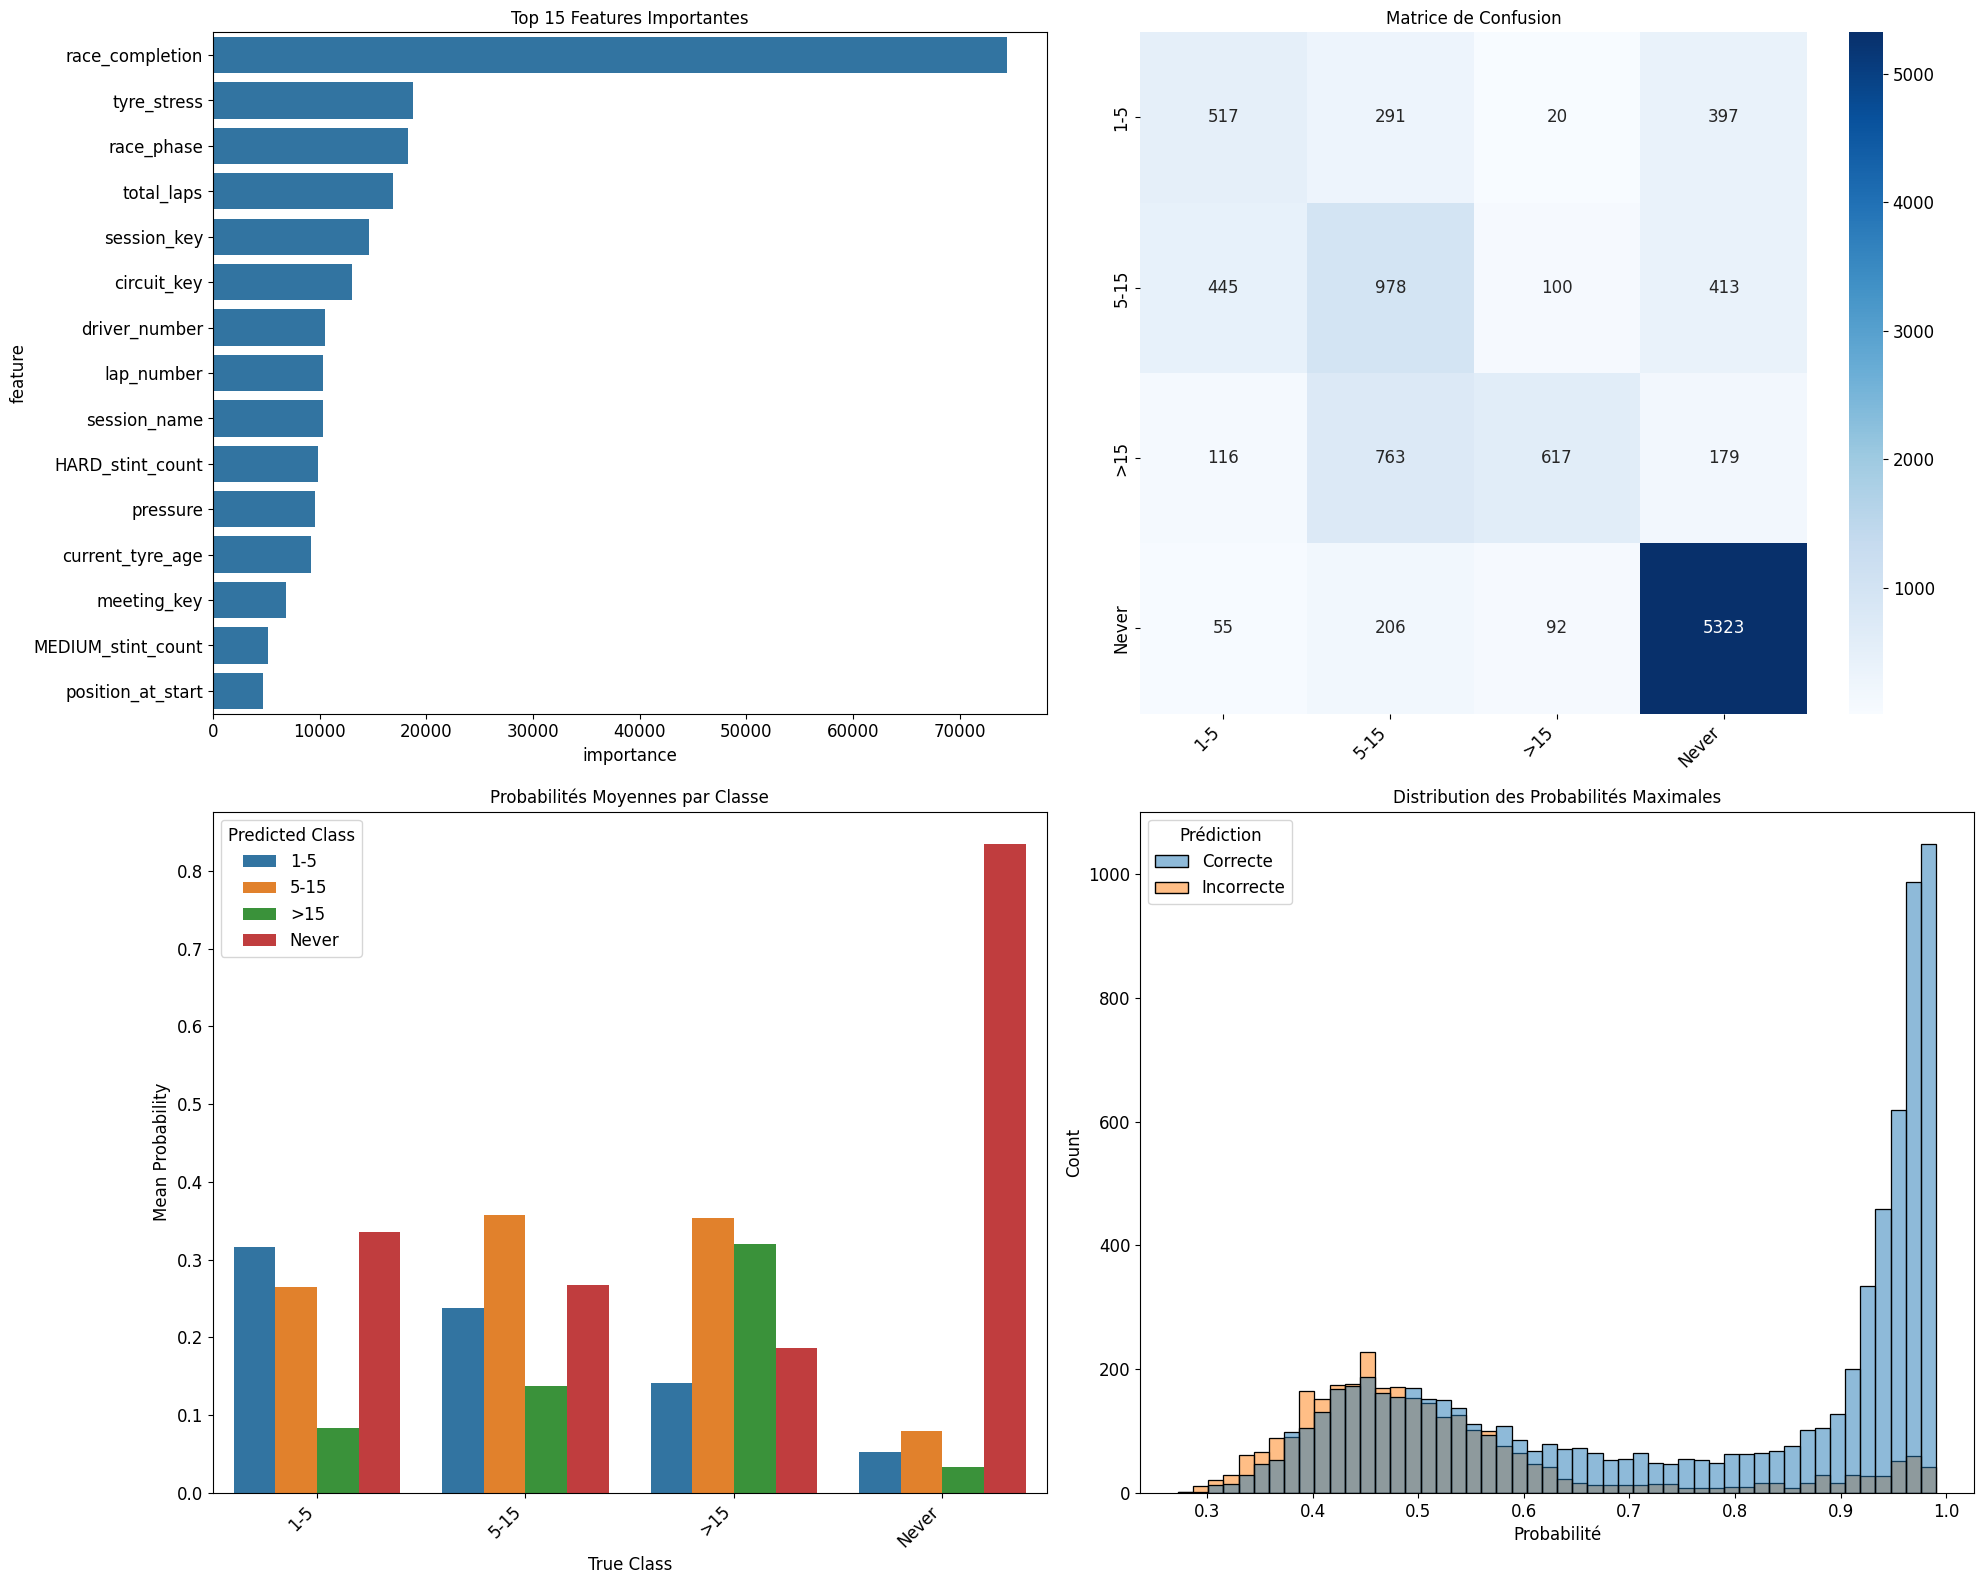

In [41]:
# Après l'entraînement de votre modèle
fig, report, feature_imp, probabilities = evaluate_model_with_probabilities(
    final_model, X_test, y_test, label_encoder
)

In [42]:
 # Sauvegarde des résultats
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
save_dir = Path("results") / timestamp
save_dir.mkdir(parents=True, exist_ok=True)
    
fig.savefig(save_dir / "visualizations.png")
final_model.save_model(save_dir / "model.txt")
feature_imp.to_csv(save_dir / "feature_importance.csv")
with open(save_dir / "report.txt", "w") as f:
    f.write(report)
    
duration = datetime.now() - start_time
logger.info(f"Processus terminé! Durée totale: {duration}")
logger.info(f"Résultats sauvegardés dans: {save_dir}")

2025-01-19 04:47:34,545 - INFO - Processus terminé! Durée totale: 2:21:57.231353
2025-01-19 04:47:34,545 - INFO - Résultats sauvegardés dans: results\20250119_044734


In [43]:
def visualize_random_predictions(model, X_test, y_test, label_encoder, n_samples=10):
    """
    Visualise les prédictions pour n tours aléatoires
    
    Args:
        model: Le modèle entraîné
        X_test: Données de test
        y_test: Labels de test
        label_encoder: Encodeur de labels
        n_samples: Nombre de tours à visualiser
    """
    # Utilisation du timestamp actuel comme graine
    current_seed = int(time.time() * 1000) % 100000
    np.random.seed(current_seed)
    
    # Sélection aléatoire des indices
    total_samples = len(X_test)
    if total_samples < n_samples:
        n_samples = total_samples
        logger.warning(f"Nombre d'échantillons réduit à {total_samples} (taille maximale disponible)")
    
    random_indices = np.random.choice(total_samples, n_samples, replace=False)
    
    # Création de la figure avec n_samples subplots
    fig = plt.figure(figsize=(15, n_samples * 3))
    
    # Obtention des prédictions pour tous les échantillons
    y_pred_proba = model.predict(X_test.iloc[random_indices])
    y_true = y_test[random_indices]
    
    # Création d'un subplot pour chaque tour
    for idx, (i, probas) in enumerate(zip(random_indices, y_pred_proba), 1):
        ax = fig.add_subplot(n_samples, 1, idx)
        
        # Création du DataFrame pour le graphique
        proba_data = pd.DataFrame({
            'Fenêtre': label_encoder.classes_,
            'Probabilité': probas
        })
        
        # Tri des fenêtres pour un affichage plus logique
        proba_data['order'] = proba_data['Fenêtre'].map(
            lambda x: (1 if 'Never' in x else 0, x)
        )
        proba_data = proba_data.sort_values('order').drop('order', axis=1)
        
        # Couleurs des barres
        colors = ['lightgray'] * len(proba_data)
        true_class_idx = np.where(label_encoder.classes_ == label_encoder.inverse_transform([y_true[idx-1]])[0])[0][0]
        colors[true_class_idx] = 'lightgreen'  # Vraie classe en vert
        pred_class_idx = np.argmax(probas)
        if pred_class_idx != true_class_idx:
            colors[pred_class_idx] = 'lightcoral'  # Prédiction incorrecte en rouge
        
        # Création du bar plot
        bars = ax.bar(proba_data['Fenêtre'], proba_data['Probabilité'], color=colors)
        
        # Ajout des valeurs sur les barres
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.2%}',
                   ha='center', va='bottom')
        
        # Formatage
        ax.set_ylim(0, 1)
        ax.set_ylabel('Probabilité')
        
        # Récupération du numéro de tour
        lap_number = X_test.iloc[i]['lap_number']
        ax.set_title(f'Index {i}, Tour {int(lap_number)} (seed: {current_seed})', pad=20)
        
        # Rotation des labels
        plt.xticks(rotation=45, ha='right')
        
        # Légende personnalisée
        from matplotlib.patches import Patch
        legend_elements = [
            Patch(facecolor='lightgreen', label='Vraie classe'),
            Patch(facecolor='lightcoral', label='Prédiction incorrecte'),
            Patch(facecolor='lightgray', label='Autres classes')
        ]
        ax.legend(handles=legend_elements, loc='upper right')
        
        # Ajout des métriques supplémentaires
        true_class = label_encoder.inverse_transform([y_true[idx-1]])[0]
        pred_class = label_encoder.inverse_transform([pred_class_idx])[0]
        metrics_text = f'Vraie fenêtre: {true_class}\nPrédiction: {pred_class}\n'
        ax.text(0.02, 0.98, metrics_text, 
                transform=ax.transAxes, 
                verticalalignment='top',
                bbox=dict(facecolor='white', alpha=0.8))
    
    plt.tight_layout()
    return fig

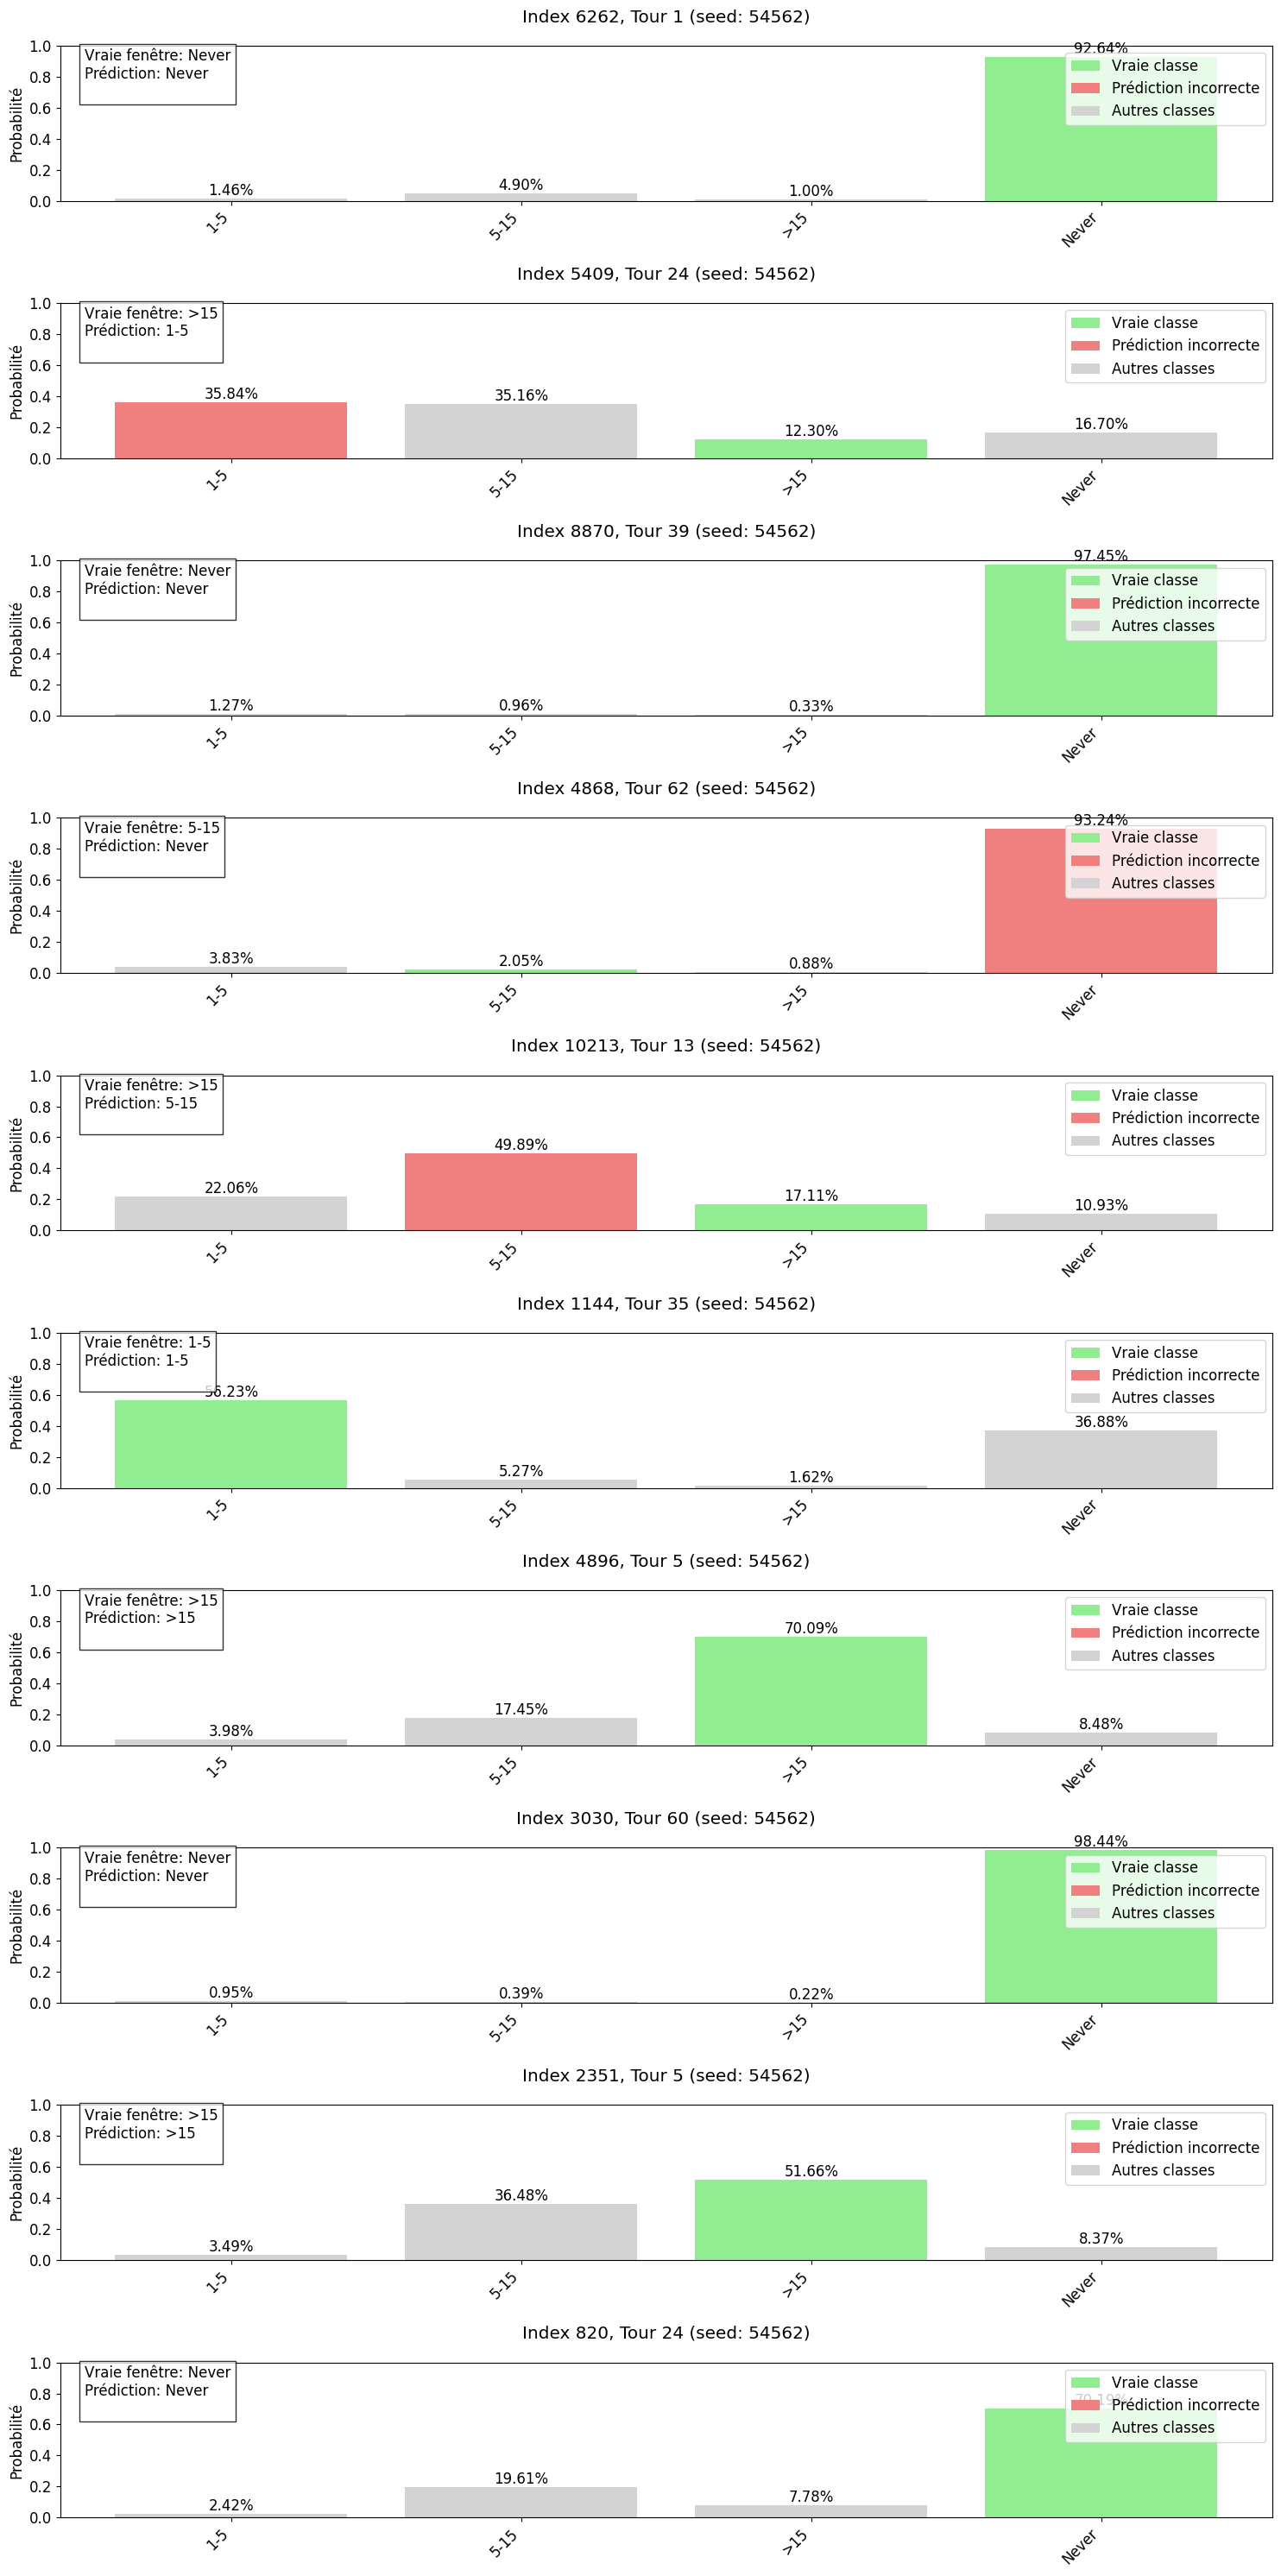

In [44]:
# Création des visualisations pour 10 tours aléatoires
fig = visualize_random_predictions(
    model=final_model,
    X_test=X_test,
    y_test=y_test,
    label_encoder=label_encoder,
    n_samples=10
)

In [45]:
def predict_and_save_results(model, X_test, label_encoder, cat_features, output_dir="predictions"):
    """
    Réalise les prédictions sur l'ensemble de test, organise les données par session_key, driver_number et lap_number,
    puis sauvegarde le tout dans des fichiers CSV et JSON dans un dossier spécifique.

    Args:
        model: Le modèle LightGBM entraîné.
        X_test: Le DataFrame de test (features).
        label_encoder: Le LabelEncoder utilisé pour encoder la target.
        cat_features: Liste des features catégorielles
        output_dir: Le dossier de sortie pour les fichiers de prédictions.
    """

    # 1. Réaliser les prédictions (probabilités)
    logger.info("Réalisation des prédictions sur l'ensemble de test...")
    y_pred_proba = model.predict(X_test, categorical_feature=cat_features)

    # 2. Créer un DataFrame avec les résultats
    logger.info("Création du DataFrame de résultats...")
    predictions_df = pd.DataFrame(y_pred_proba, columns=[f"proba_{c}" for c in label_encoder.classes_])

    # 3. Ajouter les colonnes 'session_key', 'driver_number', 'lap_number'
    logger.info("Ajout des colonnes 'session_key', 'driver_number', 'lap_number'...")
    predictions_df['session_key'] = X_test['session_key'].values.astype(int) # Convertir en int
    predictions_df['driver_number'] = X_test['driver_number'].values.astype(int) # Convertir en int
    predictions_df['lap_number'] = X_test['lap_number'].values.astype(int) # Convertir en int

    # 4. Ajouter la prédiction (classe avec la probabilité la plus élevée)
    logger.info("Ajout de la colonne de prédiction...")
    predictions_df['prediction'] = label_encoder.inverse_transform(np.argmax(y_pred_proba, axis=1))

    # 5. Réorganiser les colonnes
    logger.info("Réorganisation des colonnes...")
    cols = ['session_key', 'driver_number', 'lap_number', 'prediction'] + [col for col in predictions_df if col.startswith('proba_')]
    predictions_df = predictions_df[cols]

    # 6. Créer le dossier de sortie
    output_path = Path(output_dir) / "predictions_pitstops"
    output_path.mkdir(parents=True, exist_ok=True)

    # 7. Sauvegarder en CSV
    csv_filename = output_path / "predictions_pitstops.csv"
    logger.info(f"Sauvegarde des prédictions en CSV dans {csv_filename}...")
    predictions_df.to_csv(csv_filename, index=False)
    logger.info("Sauvegarde en CSV terminée!")

    # 8. Organiser les données pour le JSON
    logger.info("Organisation des données pour le JSON...")
    json_data = {"sessions": {}}
    for _, row in predictions_df.iterrows():
        session_key = int(row['session_key'])  # Convertir en int
        driver_number = int(row['driver_number'])  # Convertir en int
        lap_number = int(row['lap_number'])  # Convertir en int

        if session_key not in json_data["sessions"]:
            json_data["sessions"][session_key] = {"drivers": {}}
        if driver_number not in json_data["sessions"][session_key]["drivers"]:
            json_data["sessions"][session_key]["drivers"][driver_number] = {"laps": {}}

        json_data["sessions"][session_key]["drivers"][driver_number]["laps"][lap_number] = {
            "predictions": row.drop(['session_key', 'driver_number', 'lap_number']).to_dict()
        }

    # 9. Sauvegarder en JSON
    json_filename = output_path / "predictions_pitstops.json"
    logger.info(f"Sauvegarde des prédictions en JSON dans {json_filename}...")
    with open(json_filename, 'w') as f:
        json.dump(json_data, f, indent=4)
    logger.info("Sauvegarde en JSON terminée!")

In [46]:
# Appel de la fonction pour générer et sauvegarder les prédictions
predict_and_save_results(
    final_model,
    X_test,
    label_encoder,
    cat_features,
    output_dir="predictions"
)

2025-01-19 04:47:35,251 - INFO - Réalisation des prédictions sur l'ensemble de test...
2025-01-19 04:47:35,293 - INFO - Création du DataFrame de résultats...
2025-01-19 04:47:35,294 - INFO - Ajout des colonnes 'session_key', 'driver_number', 'lap_number'...
2025-01-19 04:47:35,295 - INFO - Ajout de la colonne de prédiction...
2025-01-19 04:47:35,296 - INFO - Réorganisation des colonnes...
2025-01-19 04:47:35,298 - INFO - Sauvegarde des prédictions en CSV dans predictions\predictions_pitstops\predictions_pitstops.csv...
2025-01-19 04:47:35,349 - INFO - Sauvegarde en CSV terminée!
2025-01-19 04:47:35,350 - INFO - Organisation des données pour le JSON...
2025-01-19 04:47:36,212 - INFO - Sauvegarde des prédictions en JSON dans predictions\predictions_pitstops\predictions_pitstops.json...
2025-01-19 04:47:36,384 - INFO - Sauvegarde en JSON terminée!
